# 03 · Variables nuevas y resúmenes por grupos

Hasta ahora hemos mirado los datos día a día y estado a estado. Para compararlos hacen falta variables que den
contexto y resúmenes por grupos:

- **Variables nuevas:** partes de la fecha, ola, región, tasa de positividad y letalidad aparente.
- **Resúmenes:** por ola, por región y por estado con `groupby` y `agg`, y una `pivot_table` de región × mes.

Partimos de los datos limpios que guarda el notebook 02.

## 0. Preparación

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.graficos import AZUL, GRIS, NARANJA, TEXTO, TEXTO_SUAVE, aplicar_estilo, formato_miles, miles
from src.variables import (OLAS, REGIONES, asignar_ola, asignar_region, crear_variables, encontrar_valle,
                           letalidad_aparente, partes_fecha, positividad_7d)

aplicar_estilo()

RUTA_LIMPIOS = RAIZ / "data" / "processed" / "covid_estados_limpio.csv"
RUTA_VARIABLES = RAIZ / "data" / "processed" / "covid_estados_variables.csv"
if not RUTA_LIMPIOS.exists():
    raise FileNotFoundError("Ejecuta antes los notebooks 01 y 02: generan " + str(RUTA_LIMPIOS.relative_to(RAIZ)))

datos = pd.read_csv(RUTA_LIMPIOS, parse_dates=["fecha"])
datos.shape

(20780, 20)

## 1. Partes de la fecha: año, mes y semana

Sirven para agrupar por periodos. Para la semana guardamos **la fecha del lunes con que empieza**, no su número:
el número de semana se repite cada año y la semana 53 de 2020 incluye del 1 al 3 de enero de 2021, así que el
número solo no basta para saber de qué semana se trata.

In [2]:
datos = partes_fecha(datos)
datos[["fecha", "año", "mes", "semana"]].sample(5, random_state=1).sort_values("fecha")

,fecha,año,mes,semana
10393,2020-04-14,2020,4,2020-04-13
5276,2020-06-19,2020,6,2020-06-15
5682,2020-07-29,2020,7,2020-07-27
9903,2020-12-03,2020,12,2020-11-30
20695,2020-12-13,2020,12,2020-12-07


## 2. Ola

En el notebook 01 vimos tres olas. Para poder agrupar por ellas hay que fijar dónde termina cada una, y lo hacemos
con los datos: el corte es el **valle de la media de 7 días de casos nacionales** entre dos picos. Usamos solo los
50 estados y DC, como en el resto del análisis.

In [3]:
estados = datos[~datos["es_territorio"]]
nacional = estados.groupby("fecha")[["casos_nuevos", "muertes_nuevas", "tests_nuevos"]].sum()
casos_7d = nacional["casos_nuevos"].rolling(7).mean()

valle_1 = encontrar_valle(casos_7d, "2020-05-15", "2020-07-15")   # entre el pico de abril y el de julio
valle_2 = encontrar_valle(casos_7d, "2020-08-15", "2020-10-15")   # entre el pico de julio y el de enero
print("Valle 1:", valle_1.date(), "con", formato_miles(casos_7d[valle_1]), "casos al día")
print("Valle 2:", valle_2.date(), "con", formato_miles(casos_7d[valle_2]), "casos al día")

# Las fechas están fijadas en src/variables.py (OLAS); comprobamos que coinciden con los valles.
assert [valle_1, valle_2] == list(pd.to_datetime(list(OLAS.values())[:2]))

Valle 1: 2020-06-09 con 19.893 casos al día
Valle 2: 2020-09-12 con 33.790 casos al día


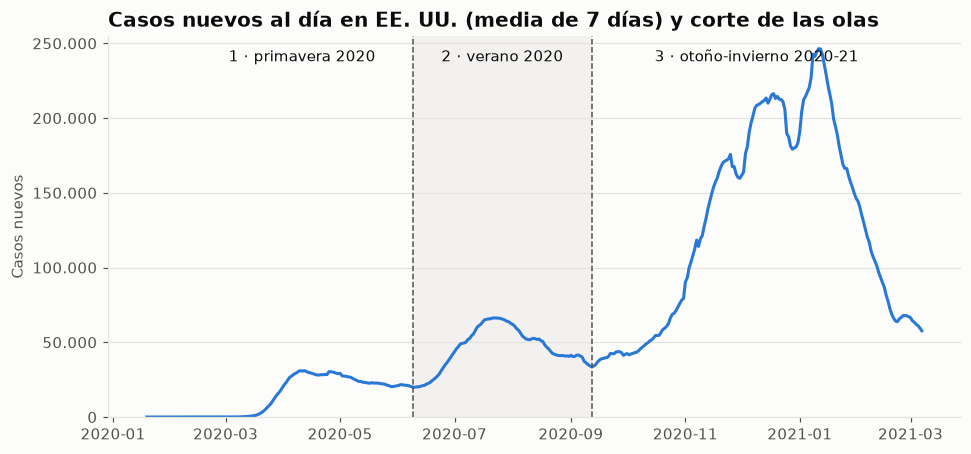

In [4]:
fig, ax = plt.subplots()
ax.plot(casos_7d.index, casos_7d, color=AZUL)
ax.axvspan(valle_1, valle_2, color=GRIS, alpha=0.15, linewidth=0)
for valle in (valle_1, valle_2):
    ax.axvline(valle, color=TEXTO_SUAVE, linewidth=1, linestyle="--")
inicio = casos_7d.index.min()
centros = [inicio + (valle_1 - inicio) * 0.6, valle_1 + (valle_2 - valle_1) / 2,
           valle_2 + (casos_7d.index.max() - valle_2) / 2]
for nombre, centro in zip(OLAS, centros):
    ax.text(centro, 238_000, nombre, ha="center", color=TEXTO, fontsize=10)
ax.set_ylim(0, 255_000)
ax.yaxis.set_major_formatter(miles)
ax.set_title("Casos nuevos al día en EE. UU. (media de 7 días) y corte de las olas")
ax.set_ylabel("Casos nuevos")
ax.grid(axis="x", visible=False)
plt.show()

In [5]:
datos = asignar_ola(datos)
datos.groupby("ola", observed=True)["fecha"].agg(["min", "max", "nunique"]).rename(
    columns={"min": "desde", "max": "hasta", "nunique": "días"})

,desde,hasta,días
ola,,,
1 · primavera 2020,2020-01-13,2020-06-09,149
2 · verano 2020,2020-06-10,2020-09-12,95
3 · otoño-invierno 2020-21,2020-09-13,2021-03-07,176


Cada ola va de un valle al siguiente. La primera incluye enero y febrero de 2020, cuando apenas había casos
notificados, y la tercera llega hasta el final de los datos (07-03-2021), cuando la curva todavía bajaba.
La variable `ola` es una **categoría ordenada**, así que las tablas y los gráficos salen en orden cronológico.

## 3. Región

Agrupamos los estados en las **cuatro regiones del Census Bureau**, la división oficial que usa el Gobierno de
EE. UU. para sus estadísticas. Los cinco territorios no pertenecen a ninguna y quedan como "Territorios".

In [6]:
datos = asignar_region(datos)
assert datos.loc[~datos["es_territorio"], "estado"].nunique() == sum(len(e) for e in REGIONES.values()) == 51
assert (datos.loc[datos["es_territorio"], "region"] == "Territorios").all()
pd.Series({region: ", ".join(sorted(lista)) for region, lista in REGIONES.items()}, name="estados").to_frame()

,estados
Noreste,"CT, MA, ME, NH, NJ, NY, PA, RI, VT"
Medio Oeste,"IA, IL, IN, KS, MI, MN, MO, ND, NE, OH, SD, WI"
Sur,"AL, AR, DC, DE, FL, GA, KY, LA, MD, MS, NC, OK..."
Oeste,"AK, AZ, CA, CO, HI, ID, MT, NM, NV, OR, UT, WA..."


## 4. Tasa de positividad

**Positividad = casos nuevos / tests nuevos.** Indica qué parte de los tests da positivo. Si sube, o hay más
contagios o se hacen pocos tests y solo se analiza a quien tiene síntomas. La OMS recomendaba mantenerla por debajo
del 5 % durante dos semanas antes de relajar las restricciones.

El cociente de un solo día no sirve: los días en que un estado notifica pocos tests (fines de semana, cambios de
sistema) salen positividades imposibles.

In [7]:
diaria = datos["casos_nuevos"] / datos["tests_nuevos"].where(datos["tests_nuevos"] > 0)
semanal = positividad_7d(datos, maximo=None)
pd.DataFrame({
    "cociente de un día": {"filas > 100 %": int((diaria > 1).sum()), "desviación típica": round(diaria.std(), 2)},
    "suma de 7 días": {"filas > 100 %": int((semanal > 1).sum()), "desviación típica": round(semanal.std(), 2)},
}).T

,filas > 100 %,desviación típica
cociente de un día,39.0,3.86
suma de 7 días,17.0,1.65


In [8]:
datos.loc[semanal > 1, ["fecha", "estado", "casos_nuevos", "tests_nuevos"]].assign(
    casos_por_test_7d=semanal[semanal > 1].round(1)).head(8)

,fecha,estado,casos_nuevos,tests_nuevos,casos_por_test_7d
4081,2020-03-09,GA,5.0,6.0,1.7
8902,2020-03-10,MI,156.0,3.0,159.3
8903,2020-03-11,MI,199.0,1.0,163.2
8904,2020-03-12,MI,270.0,24.0,32.0
8905,2020-03-13,MI,364.0,21.0,24.9
8906,2020-03-14,MI,367.0,27.0,20.3
8907,2020-03-15,MI,460.0,33.0,17.8
8908,2020-03-16,MI,707.0,156.0,9.5


Por eso **sumamos los casos y los tests de 7 días antes de dividir**. Aun así quedan 17 filas por encima del 100 %,
12 de ellas en Michigan a principios de marzo de 2020: su serie de tests empieza días después que la de casos (hay
días con 156 casos y 3 tests). No son valores posibles, así que `positividad_7d` los deja como `NaN`.

Hay una limitación más: **cada estado cuenta los tests a su manera** (`fuente_tests`, notebook 01), y cada estado
usa siempre la misma.

In [9]:
datos["positividad_7d"] = positividad_7d(datos)
estados = datos[~datos["es_territorio"]]
(estados.groupby("fuente_tests")
    .agg(estados=("estado", "nunique"), casos=("casos_nuevos", "sum"), tests=("tests_nuevos", "sum"),
         mediana_semanal=("positividad_7d", "median"))
    .assign(positividad_total=lambda t: (t["casos"] / t["tests"] * 100).round(1),
            mediana_semanal=lambda t: (t["mediana_semanal"] * 100).round(1))
    .drop(columns=["casos", "tests"])
    .sort_values("positividad_total"))

,estados,mediana_semanal,positividad_total
fuente_tests,,,
totalTestEncountersViral,14,5.2,6.6
totalTestsViral,28,5.8,8.0
posNeg,7,10.4,10.3
totalTestsPeopleViral,2,17.5,22.3


Los estados que cuentan **personas** (`totalTestsPeopleViral`, `posNeg`) salen con más positividad que los que
cuentan **muestras** (`totalTestsViral`, `totalTestEncountersViral`): una persona que se hace tres tests es un
solo test en el primer caso y tres en el segundo. Así que la positividad **sirve para seguir a un estado en el
tiempo, pero no para comparar dos estados que cuentan distinto**. En los resúmenes por región se mezclan las dos
formas de contar, y hay que leerlos como orientativos.

## 5. Letalidad aparente

**Letalidad aparente = muertes acumuladas / casos acumulados.** Es "aparente" porque solo cuenta los casos
detectados: con pocos tests, muchos casos leves no se registran y la letalidad sale más alta de lo que es. No
la calculamos hasta que el estado tiene 1.000 casos, porque con pocos casos el cociente salta mucho.

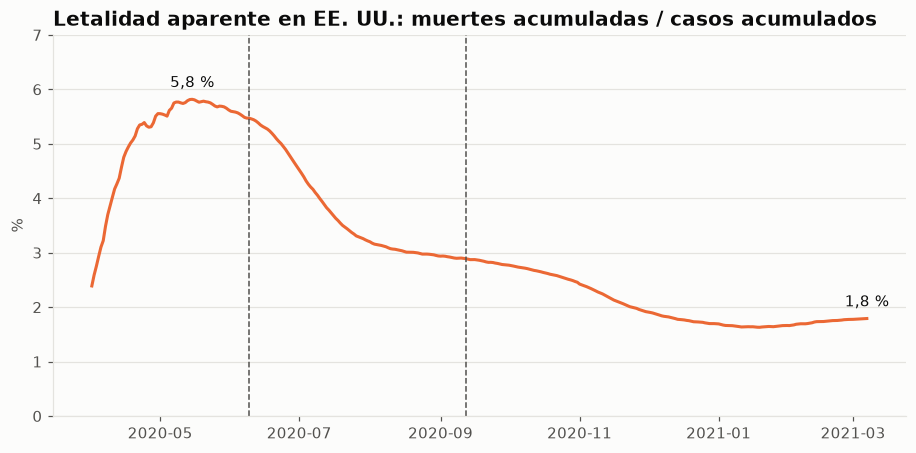

In [10]:
datos["letalidad_aparente"] = letalidad_aparente(datos)
estados = datos[~datos["es_territorio"]]

acumulados = estados.groupby("fecha")[["muertes_acum", "casos_acum"]].sum().loc["2020-04-01":]
letalidad_nacional = acumulados["muertes_acum"] / acumulados["casos_acum"] * 100

fig, ax = plt.subplots()
ax.plot(letalidad_nacional.index, letalidad_nacional, color=NARANJA)
for valle in (valle_1, valle_2):
    ax.axvline(valle, color=TEXTO_SUAVE, linewidth=1, linestyle="--")
maximo = letalidad_nacional.idxmax()
for fecha in (maximo, letalidad_nacional.index[-1]):
    ax.annotate(f"{letalidad_nacional[fecha]:.1f} %".replace(".", ","), xy=(fecha, letalidad_nacional[fecha]),
                xytext=(0, 8), textcoords="offset points", ha="center", color=TEXTO)
ax.set_ylim(0, 7)
ax.set_title("Letalidad aparente en EE. UU.: muertes acumuladas / casos acumulados")
ax.set_ylabel("%")
ax.grid(axis="x", visible=False)
plt.show()

La letalidad aparente llega a su máximo en mayo de 2020 (5,8 %) y después **baja de forma continua hasta cerca
del 1,7 % en enero de 2021**. Al final repunta un poco (1,8 %), cuando llegan las muertes de los casos del pico de
invierno: las muertes van unas tres semanas por detrás de los casos (notebook 01). La explicación principal de la
bajada está en los tests: en la primera ola se hacían muy pocos (apartado 6) y solo se detectaban
los casos graves. Una parte de la bajada puede deberse también a la mejora del tratamiento, pero con estos datos no
se puede separar una cosa de la otra. Las líneas discontinuas marcan los cortes de las olas.

## 6. Resúmenes con `groupby` y `agg`

### 6.1 Por ola

Sumamos todos los estados por día y resumimos cada ola. La positividad y la letalidad de la ola se calculan con
**los totales de la ola** (casos de la ola / tests de la ola), no como media de los cocientes diarios: así un día con
pocos datos pesa lo mismo que sus casos, no lo mismo que un día normal.

In [11]:
nacional = asignar_ola(estados.groupby("fecha")[["casos_nuevos", "muertes_nuevas", "tests_nuevos"]].sum()
                       .assign(casos_7d=lambda t: t["casos_nuevos"].rolling(7).mean()).reset_index())
por_ola = nacional.groupby("ola", observed=True).agg(
    días=("fecha", "nunique"),
    casos=("casos_nuevos", "sum"),
    muertes=("muertes_nuevas", "sum"),
    tests=("tests_nuevos", "sum"),
    pico_casos_7d=("casos_7d", "max"),
)
por_ola["positividad_%"] = (por_ola["casos"] / por_ola["tests"] * 100).round(1)
por_ola["letalidad_%"] = (por_ola["muertes"] / por_ola["casos"] * 100).round(1)
por_ola["tests_por_caso"] = (por_ola["tests"] / por_ola["casos"]).round(1)
por_ola.style.format({c: formato_miles for c in ["casos", "muertes", "tests", "pico_casos_7d"]}).format(
    "{:.1f}".format, subset=["positividad_%", "letalidad_%", "tests_por_caso"], decimal=",")

,días,casos,muertes,tests,pico_casos_7d,positividad_%,letalidad_%,tests_por_caso
ola,,,,,,,,
1 · primavera 2020,149,1.968.995,107.925,22.459.458,31.064,"8,8","5,5","11,4"
2 · verano 2020,95,4.451.116,77.751,73.580.960,66.341,"6,0","1,7","16,5"
3 · otoño-invierno 2020-21,176,22.232.559,328.296,267.850.517,246.419,"8,3","1,5","12,0"


- **La tercera ola fue la peor con diferencia:** más de 22 millones de casos y unas 330.000 muertes, más que las dos
  primeras juntas.
- **La primera ola tuvo la letalidad más alta (5,5 %)** y la menor cantidad de tests: 11,4 por caso, frente a
  16,5 en la segunda. Encaja con lo del apartado 5: se detectaba sobre todo a los enfermos graves.
- La **positividad de la tercera ola (8,3 %)** vuelve a niveles de la primera aunque se hicieran 12 veces más tests:
  los contagios crecieron más deprisa que la capacidad de hacer tests.

### 6.2 Por región y ola

¿Golpeó cada ola a las mismas zonas del país? Calculamos qué parte de los casos de cada ola corresponde a cada
región. Como referencia ponemos el **peso de cada región en la población** (censo de 2020): si una región solo
tuviera los casos que le tocan por población, su barra llegaría hasta la marca gris.

In [12]:
# Población del censo de 2020 (Census Bureau), en % del total de los 50 estados y DC.
PESO_POBLACION = pd.Series({"Noreste": 17.4, "Medio Oeste": 20.8, "Sur": 38.1, "Oeste": 23.7})

region_ola = estados.groupby(["ola", "region"], observed=True).agg(
    casos=("casos_nuevos", "sum"), muertes=("muertes_nuevas", "sum"))
reparto = region_ola / region_ola.groupby(level="ola", observed=True).transform("sum") * 100
reparto.round(1).unstack("region").reindex(columns=list(REGIONES), level="region")

casos                         muertes  \
region                     Noreste Medio Oeste   Sur Oeste Noreste   
ola                                                                  
1 · primavera 2020            40.3        20.2  26.4  13.1    53.2   
2 · verano 2020                4.9        15.6  54.9  24.6     9.6   
3 · otoño-invierno 2020-21    16.1        22.5  38.1  23.3    15.6   

                                                    
region                     Medio Oeste   Sur Oeste  
ola                                                 
1 · primavera 2020                19.3  18.5   9.1  
2 · verano 2020                   12.7  54.8  22.8  
3 · otoño-invierno 2020-21        23.6  38.9  21.9

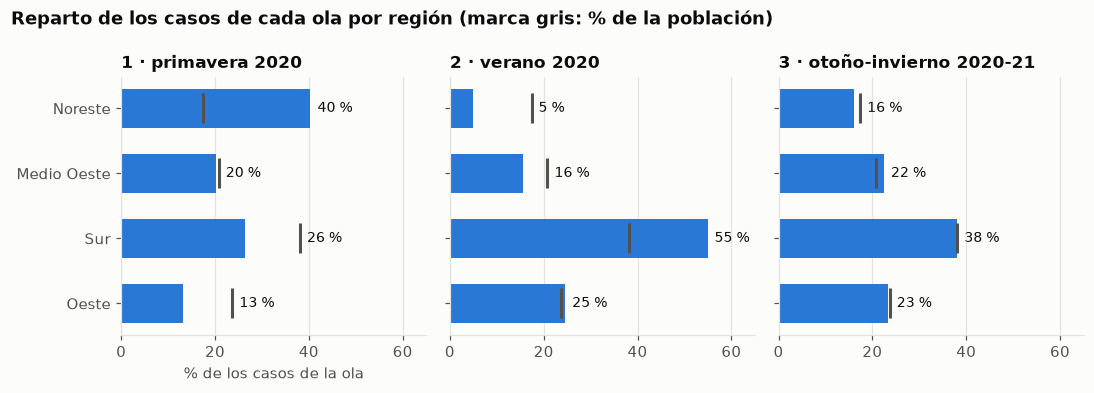

In [13]:
orden = list(REGIONES)[::-1]
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.6), sharex=True, sharey=True)
for ax, ola in zip(ejes, OLAS):
    valores = reparto.loc[ola, "casos"].reindex(orden)
    ax.barh(orden, valores, color=AZUL, height=0.6)
    ax.scatter(PESO_POBLACION.reindex(orden), orden, marker="|", s=400, color=TEXTO_SUAVE, linewidths=2, zorder=3)
    for posicion, (valor, peso) in enumerate(zip(valores, PESO_POBLACION.reindex(orden))):
        ax.text(max(valor, peso) + 1.5, posicion, f"{valor:.0f} %", va="center", color=TEXTO, fontsize=9)
    ax.set_title(ola, fontsize=11)
    ax.set_xlim(0, 65)
    ax.set_axisbelow(True)
    ax.grid(axis="y", visible=False)
ejes[0].set_xlabel("% de los casos de la ola")
fig.suptitle("Reparto de los casos de cada ola por región (marca gris: % de la población)",
             x=0.01, ha="left", fontweight="bold", color=TEXTO)
plt.tight_layout()
plt.show()

Cada ola tuvo su zona:

- **Ola 1 (primavera):** el **Noreste** tuvo el 40 % de los casos y el 53 % de las muertes con solo el 17 % de la
  población. Es la ola de Nueva York y Nueva Jersey.
- **Ola 2 (verano):** se desplazó al **Sur**, con el 55 % de los casos (Texas, Florida, Georgia…), y el Noreste
  bajó al 5 %.
- **Ola 3 (otoño-invierno):** fue **la de todo el país**. El reparto se parece mucho al de la población: ninguna
  región se separa de su marca gris más de dos puntos.

### 6.3 Por estado y ola

Con dos claves de agrupación y varias agregaciones a la vez vemos qué estados concentraron las muertes de cada ola.

In [14]:
estado_ola = estados.groupby(["ola", "estado"], observed=True).agg(
    casos=("casos_nuevos", "sum"),
    muertes=("muertes_nuevas", "sum"),
    peor_dia_muertes=("muertes_nuevas", "max"),
    positividad_media=("positividad_7d", "mean"),
)
cinco_peores = estado_ola.groupby(level="ola", observed=True, group_keys=False).apply(lambda t: t.nlargest(5, "muertes"))
cinco_peores.style.format({"casos": formato_miles, "muertes": formato_miles, "peor_dia_muertes": formato_miles,
                           "positividad_media": lambda x: f"{x:.1%}".replace(".", ",")})

In [15]:
peor_ola = (estado_ola["muertes"].unstack("ola").idxmax(axis=1).value_counts()
            .reindex(list(OLAS), fill_value=0).rename("estados"))
print("Ola con más muertes en cada estado:")
print(peor_ola.to_string())
print("\nEstados cuya peor ola fue la primera:",
      ", ".join(estado_ola["muertes"].unstack("ola").idxmax(axis=1).loc[lambda s: s == list(OLAS)[0]].index))

Ola con más muertes en cada estado:
1 · primavera 2020             5
2 · verano 2020                0
3 · otoño-invierno 2020-21    46

Estados cuya peor ola fue la primera: CT, DC, MA, NJ, NY


- En la primera ola, los cinco estados con más muertes son del **Noreste o del Medio Oeste** (Nueva York, Nueva
  Jersey, Massachusetts, Pensilvania e Illinois). En la segunda, del **Sur y del Oeste** (Texas, Florida, California,
  Arizona y Georgia).
- En la tercera, los primeros puestos son de los **estados más poblados** (California, Texas, Florida…). La lista
  refleja sobre todo el tamaño; la comparación justa por habitante llega en la issue #6.
- Para 46 de los 51 **la peor ola fue la tercera**. Solo cinco tuvieron más muertes en la primavera de 2020 (Nueva
  York, Nueva Jersey, Massachusetts, Connecticut y Washington D. C.) y ninguno en verano.
- `peor_dia_muertes` es la cifra diaria más alta del estado en esa ola: California llegó a 1.114 muertes en un
  solo día (25-02-2021). Para comparar estados usamos los totales, porque un solo día puede incluir registros
  atrasados (notebook 02).

## 7. `pivot_table`: positividad por región y mes

La tabla dinámica pone las regiones en filas y los meses en columnas. Como en el apartado 6.1, primero sumamos
casos y tests de cada celda y después dividimos. Empezamos en marzo de 2020 porque antes apenas había tests, y
marzo de 2021 solo tiene 7 días.

In [16]:
desde_marzo = estados[estados["fecha"] >= "2020-03-01"].assign(mes_año=lambda t: t["fecha"].dt.to_period("M"))
tabla = desde_marzo.pivot_table(index="region", columns="mes_año", values=["casos_nuevos", "tests_nuevos"],
                                aggfunc="sum")
positividad_mes = (tabla["casos_nuevos"] / tabla["tests_nuevos"] * 100).reindex(list(REGIONES))
positividad_mes.round(1)

mes_año,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12,2021-01,2021-02,2021-03
region,,,,,,,,,,,,,
Noreste,27.3,29.3,7.2,1.8,1.7,1.3,1.2,2.0,4.6,7.6,7.2,4.0,3.4
Medio Oeste,16.3,15.3,7.5,3.5,4.6,4.9,5.1,7.4,13.6,12.0,8.8,4.4,3.4
Sur,9.5,10.4,6.0,7.4,11.2,9.0,6.5,6.5,10.4,13.8,14.5,9.2,7.2
Oeste,9.0,7.1,4.4,5.8,7.7,5.7,3.7,4.6,8.2,11.6,10.5,4.2,2.6


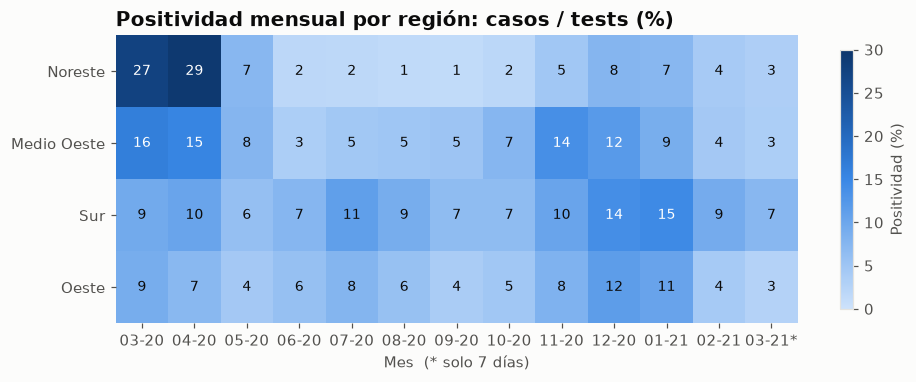

In [17]:
azules = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf",
                                                      "#184f95", "#0d366b"])
fig, ax = plt.subplots(figsize=(10, 3.4))
imagen = ax.imshow(positividad_mes.values, cmap=azules, aspect="auto", vmin=0, vmax=30)
for fila, region in enumerate(positividad_mes.index):
    for columna, valor in enumerate(positividad_mes.loc[region]):
        ax.text(columna, fila, f"{valor:.0f}", ha="center", va="center", fontsize=9,
                color="white" if valor > 12 else TEXTO)
etiquetas = [f"{p:%m-%y}" for p in positividad_mes.columns]
etiquetas[-1] += "*"
ax.set_xticks(range(len(etiquetas)), etiquetas)
ax.set_yticks(range(len(positividad_mes.index)), positividad_mes.index)
ax.grid(False)
for borde in ax.spines.values():
    borde.set_visible(False)
fig.colorbar(imagen, ax=ax, label="Positividad (%)", shrink=0.9)
ax.set_title("Positividad mensual por región: casos / tests (%)")
ax.set_xlabel("Mes  (* solo 7 días)")
plt.show()

- **Noreste, primavera de 2020:** cerca del 30 % de los tests daban positivo. Con tan pocos tests solo se analizaba
  a quien tenía síntomas claros. Después baja a menos del 2 % en verano: el Noreste controló la primera ola y
  pasó a hacer muchos tests.
- **Sur:** es la región que **nunca bajó del 5 %** desde junio. Tiene su máximo de verano en julio (11 %) y su
  máximo absoluto en enero de 2021 (casi un 15 %).
- **Medio Oeste:** su peor mes de la tercera ola es **noviembre de 2020** (14 %), antes que el resto. Allí la ola
  de otoño empezó antes.
- En febrero y marzo de 2021 todas las regiones bajan, en línea con el final de la tercera ola.

Recordatorio: cada región mezcla estados que cuentan personas y otros que cuentan muestras (apartado 4), así que
estas cifras sirven para ver tendencias, no para dar valores exactos.

## 8. Guardar los datos con las variables nuevas

In [18]:
# Comprobamos que la función que usarán los siguientes notebooks da lo mismo que los pasos de este.
completo = crear_variables(pd.read_csv(RUTA_LIMPIOS, parse_dates=["fecha"]))
pd.testing.assert_frame_equal(completo, datos)

datos.to_csv(RUTA_VARIABLES, index=False)
print("Guardado:", RUTA_VARIABLES.relative_to(RAIZ), datos.shape)
print("Columnas nuevas:", ", ".join(["año", "mes", "semana", "ola", "region", "positividad_7d",
                                     "letalidad_aparente"]))

Guardado: data\processed\covid_estados_variables.csv (20780, 27)
Columnas nuevas: año, mes, semana, ola, region, positividad_7d, letalidad_aparente


## Conclusiones

- **Siete variables nuevas:** `año`, `mes`, `semana`, `ola`, `region`, `positividad_7d` y `letalidad_aparente`.
  Las dos tasas se calculan con sumas (7 días o el total del grupo), nunca como media de cocientes diarios.
- **Las olas se cortan con los datos:** valles del 9 de junio y del 12 de septiembre de 2020.
- **Cada ola tuvo su zona:** el Noreste en primavera, el Sur en verano y todo el país en otoño-invierno.
- **La letalidad aparente bajó de más del 5 % a menos del 2 %,** sobre todo porque al principio casi no se hacían
  tests y solo se detectaban los casos graves.
- **La positividad** es útil para seguir un estado en el tiempo, pero no para comparar estados que cuentan los tests
  de forma distinta.